# 14 — MURA all-anatomy study-level fine-tuned ResNet-18

This notebook reports one controlled Model B training run per anatomy. It is a development/validation experiment only: the historical official MURA `valid` split is not read.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

def locate_project_root():
    for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (candidate / "CHARTER.md").exists():
            return candidate
    raise RuntimeError("Run this notebook from inside the repository checkout.")

ROOT = locate_project_root()
RUNTIME = ROOT.parent / 'runtime' / 'multianatomy_v1'
FINE = RUNTIME / 'finetuned_all_v1'
COMPARISON = RUNTIME / 'model_comparison_v1'
SHORTCUT = RUNTIME / 'shortcut_audit_v1'
assert ROOT.name == 'mura-wrist-ml-pipeline', ROOT
print('Notebook environment configured; results are loaded from saved development artifacts.')


Notebook environment configured; results are loaded from saved development artifacts.


In [2]:
provenance = json.loads((FINE / 'finetuned_provenance.json').read_text(encoding='utf-8'))
assert provenance['official_valid_read'] is False
assert provenance['test_used_for_selection'] is False
display(Markdown('**Safety check passed:** no official MURA `valid`/test prediction was used.'))
display(pd.DataFrame([{
    'initialization': provenance['initialization'],
    'architecture': provenance['architecture'],
    'maximum epochs': provenance['max_epochs'],
    'early stopping': provenance['early_stopping'],
    'operating policy': provenance['operating_policy'],
}]))

**Safety check passed:** no official MURA `valid`/test prediction was used.

,initialization,architecture,maximum epochs,early stopping,operating policy
0,ImageNet ResNet-18; no historical wrist checkp...,per-view ResNet-18 probabilities mean-pooled t...,15,"{'monitor': 'validation AUROC', 'patience': 4}",highest validation threshold at sensitivity >=...


In [3]:
metrics = pd.read_csv(FINE / 'finetuned_metrics_by_anatomy.csv')
display(metrics[[
    'anatomy', 'n_studies', 'threshold', 'auroc', 'auprc', 'sensitivity',
    'specificity', 'precision', 'f1', 'false_negative', 'false_positive', 'flagged_percent', 'runtime_seconds'
]].round(4))

,anatomy,n_studies,threshold,auroc,auprc,sensitivity,specificity,precision,f1,false_negative,false_positive,flagged_percent,runtime_seconds
0,XR_ELBOW,345,0.0339,0.9083,0.8935,0.9538,0.4140,0.4960,0.6526,6,126,72.4638,3362.638
1,XR_FINGER,392,0.0197,0.8570,0.7346,0.9535,0.3992,0.4377,0.6000,6,158,71.6837,3547.688
2,XR_FOREARM,183,0.1892,0.8438,0.7239,0.9636,0.3359,0.3841,0.5492,2,85,75.4098,444.978
3,XR_HAND,411,0.0008,0.7924,0.6537,0.9533,0.2763,0.3168,0.4755,5,220,78.3455,3550.166
4,XR_HUMERUS,118,0.1742,0.8785,0.8750,0.9636,0.4127,0.5889,0.7310,2,37,76.2712,553.166
5,XR_SHOULDER,567,0.2533,0.8471,0.8567,0.9522,0.2664,0.5812,0.7219,14,201,84.6561,2148.357
6,XR_WRIST,708,0.0061,0.9083,0.8783,0.9522,0.4427,0.5159,0.6693,13,243,70.9040,6147.920


In [4]:
ci_rows = []
for anatomy in sorted(metrics['anatomy'].unique()):
    ci = pd.read_csv(FINE / anatomy.lower() / 'patient_bootstrap_ci.csv')
    ci['anatomy'] = anatomy
    ci_rows.append(ci)
bootstrap_ci = pd.concat(ci_rows, ignore_index=True)
display(bootstrap_ci[bootstrap_ci['metric'].isin(['auroc', 'auprc', 'sensitivity', 'specificity'])][['anatomy', 'metric', 'estimate', 'lower_95_ci', 'upper_95_ci', 'valid_resamples']].round(4))

,anatomy,metric,estimate,lower_95_ci,upper_95_ci,valid_resamples
0,XR_ELBOW,auroc,0.9083,0.8719,0.9422,2000
1,XR_ELBOW,auprc,0.8935,0.8463,0.9336,2000
2,XR_ELBOW,sensitivity,0.9538,0.9160,0.9856,2000
3,XR_ELBOW,specificity,0.4140,0.3476,0.4833,2000
6,XR_FINGER,auroc,0.8570,0.8139,0.8941,2000
7,XR_FINGER,auprc,0.7346,0.6502,0.8255,2000
8,XR_FINGER,sensitivity,0.9535,0.9141,0.9849,2000
9,XR_FINGER,specificity,0.3992,0.3412,0.4565,2000
12,XR_FOREARM,auroc,0.8438,0.7736,0.9041,2000
13,XR_FOREARM,auprc,0.7239,0.5921,0.8335,2000


,anatomy,best_epoch,epoch,train_loss,validation_auroc,learning_rate
14,XR_ELBOW,15,15,0.1880,0.9083,0.0000
28,XR_FINGER,14,14,0.1997,0.8570,0.0000
30,XR_FOREARM,1,1,0.6439,0.8438,0.0001
49,XR_HAND,15,15,0.1959,0.7924,0.0000
55,XR_HUMERUS,6,6,0.3562,0.8785,0.0001
61,XR_SHOULDER,2,2,0.5824,0.8471,0.0001
76,XR_WRIST,11,11,0.1720,0.9083,0.0000


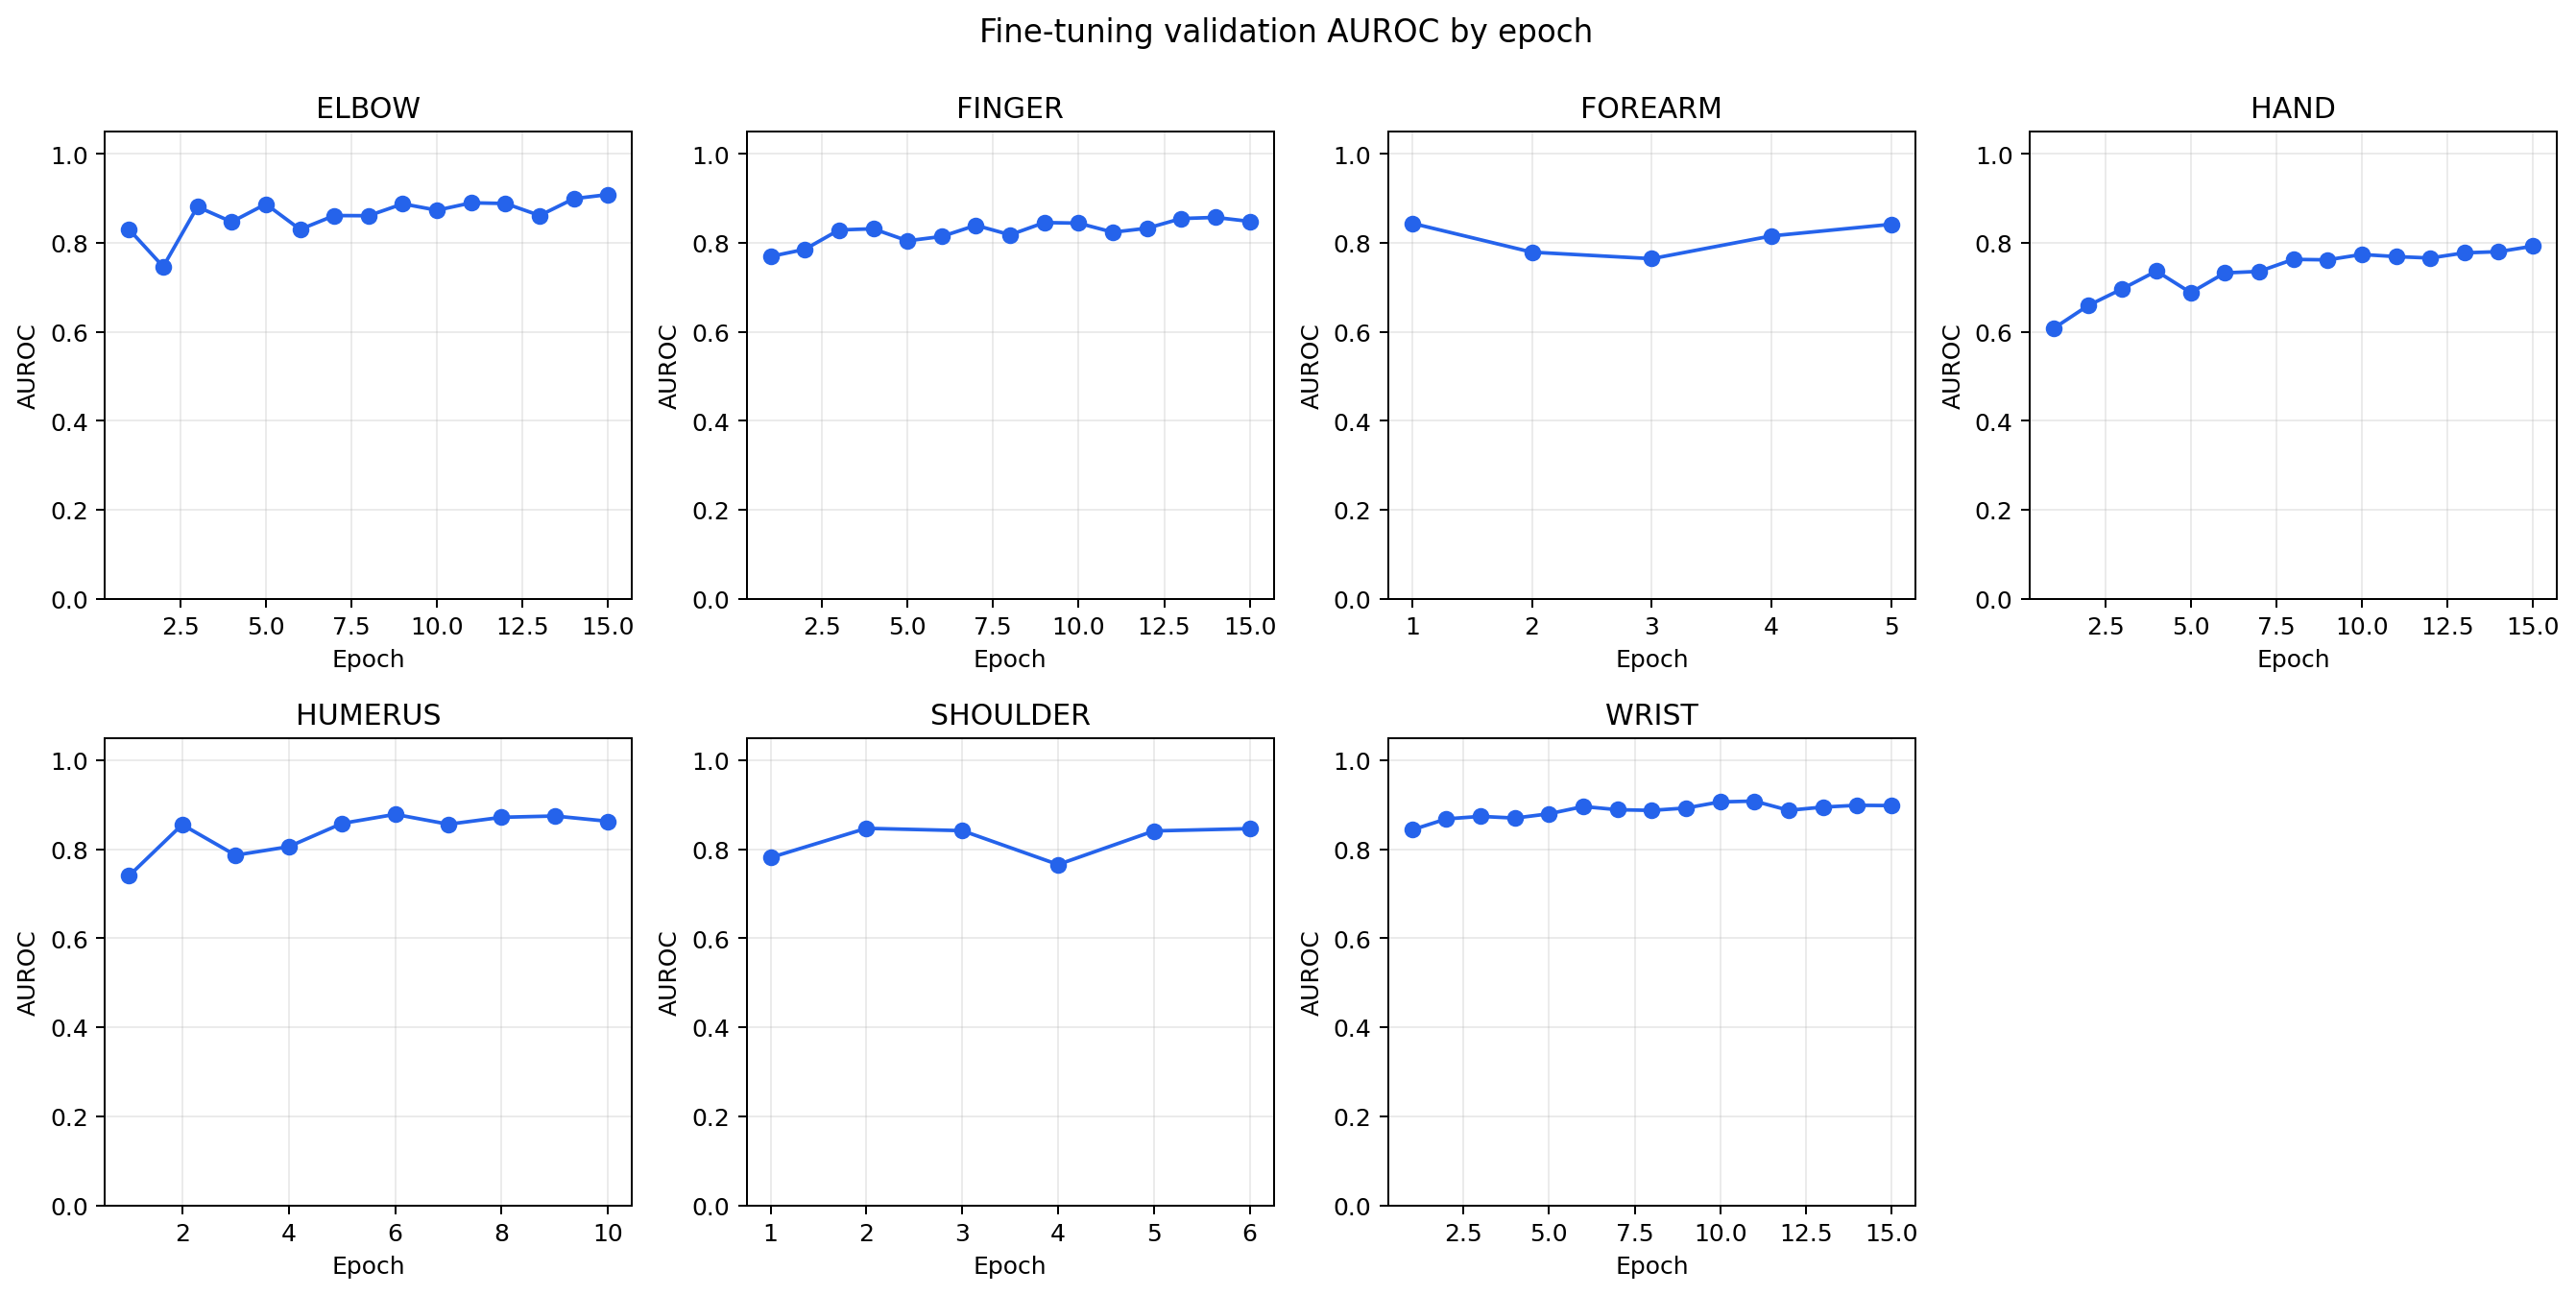

In [5]:
history = pd.read_csv(COMPARISON / 'training_history_by_anatomy.csv')
best = history.sort_values('validation_auroc').groupby('anatomy', as_index=False).tail(1)
display(best[['anatomy', 'best_epoch', 'epoch', 'train_loss', 'validation_auroc', 'learning_rate']].sort_values('anatomy').round(4))
display(Image(filename=str(COMPARISON / 'finetuned_training_history.png')))

### What the model learns

A view is passed through ResNet-18 to produce an abnormality probability. The real-view probabilities within the same study are mean-pooled, and the loss is computed once per study. Padding views are masked and cannot influence the study score. This is not attention pooling and it is not lesion localization.